# Fine-tune FinBERT-EMAS (Track XAU) — FR-6 / M2 + M6

Notebook ini **memverifikasi dan mengeksplorasi**, bukan jalur produksi.
Jalur yang reprodusibel ada di:

```
python -m scripts.train_xau_finbert     # latih + kalibrasi + tulis artefak
python -m scripts.eval_xau_finbert      # evaluasi artefak beku
```

Alasannya: notebook mudah dieksekusi dengan urutan sel yang salah dan
tanpa jejak seed. Skrip adalah sumber kebenaran; notebook dipakai untuk
melihat kenapa hasilnya begitu.

**Kontrak yang dikunci repo** (jangan diubah di sini):
- label: `Positive → 2`, `Neutral → 1`, `Negative → 0`
- `Price Sentiment: none` **dibuang**
- protokol probabilitas `[p_pos, p_neu, p_neg]`

## 0. Setup

In [2]:
import sys
from pathlib import Path


def _find_repo_root(start: Path) -> Path:
    """Naik sampai ketemu pyproject.toml — jangan asumsikan kedalaman folder."""
    for cand in [start, *start.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    raise RuntimeError(f"root repo tidak ditemukan dari {start}")


ROOT = _find_repo_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from model.xau.src.data_loader import (  # noqa: E402
    load_gold_test,
    load_gold_train,
    split_train_val,
)

print("ROOT:", ROOT)
print("CUDA:", end=" ")
try:
    import torch

    print(torch.cuda.is_available(), "|",
          torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-")
except ImportError:
    print("torch belum terpasang — sel pelatihan tidak bisa dijalankan")


ROOT: /home/josjiez/Documents/FInews
CUDA: True | NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 1. Seperti apa datanya

Korpus **campuran bahasa Inggris**, dominan media India + AS
(`marketwatch.com`, `economictimes.indiatimes.com`, `moneycontrol.com`).
Rentang nyata **2000-02 s.d. 2019-02**, bukan 2021 seperti klaim README
sumber. Ini penting untuk bab keterbatasan: model tidak pernah melihat
rezim harga emas pasca-2020.

In [3]:
tr = load_gold_train()
te = load_gold_test()
print(f"train {len(tr):,} | test {len(te):,}")
print()
print(tr["tone"].value_counts().to_string())
print()
print("rentang tanggal:", tr["date"].min().date(), "->", tr["date"].max().date())
print("tanggal tak terbaca:", int(tr["date"].isna().sum()))
tr.head(5)

train 6,882 | test 1,720

tone
positive    3531
negative    3050
neutral      301

rentang tanggal: 2000-02-15 -> 2019-01-31
tanggal tak terbaca: 106


,text,label,tone,date
0,gold prices recover on buying support,2,positive,2007-12-25
1,"February gold falls $7.20, or 0.7%, at $1,183....",0,negative,2016-11-30
2,gold broke out and then broke down,0,negative,2018-04-16
3,spot gold quoted at $707.10 in asia trade,2,positive,2006-05-10
4,"dec. gold settles at $1,124.60/oz on comex, do...",0,negative,2015-08-26


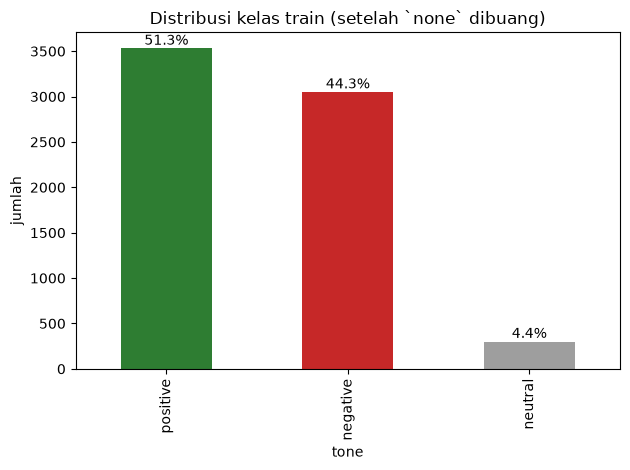

In [4]:
vc = tr["tone"].value_counts()
ax = vc.plot(kind="bar", color=["#2e7d32", "#c62828", "#9e9e9e"][: len(vc)])
ax.set_title("Distribusi kelas train (setelah `none` dibuang)")
ax.set_ylabel("jumlah")
for i, v in enumerate(vc.values):
    ax.text(i, v + 40, f"{v / len(tr):.1%}", ha="center")
plt.tight_layout()
plt.show()


## 2. Panjang teks → batas `max_length`

Korpus ini isinya **headline**, bukan artikel penuh. Kalau `max_length`
dipatok 512 seperti konfigurasi umum FinBERT, kita membuang komputasi
untuk padding yang tidak membawa informasi.

In [5]:
wc = tr["text"].str.split().str.len()
print(wc.describe().to_string())
print()
for p in (50, 90, 95, 99):
    print(f"persentil {p}: {np.percentile(wc, p):.0f} kata")
print()
print(f"teks > 96 kata: {(wc > 96).mean():.2%}  (dipotong, informasi hilang minimal)")

count    6882.000000
mean        8.904824
std         2.067972
min         1.000000
25%         8.000000
50%         9.000000
75%        10.000000
max        20.000000

persentil 50: 9 kata
persentil 90: 12 kata
persentil 95: 12 kata
persentil 99: 15 kata

teks > 96 kata: 0.00%  (dipotong, informasi hilang minimal)


## 3. Validasi tidak boleh bocor

Split `test` parquet adalah **holdout murni**. Validation diambil dari
*train* dengan stratifikasi, supaya kelas `neutral` tetap terwakili dan
tidak ada teks yang muncul di dua sisi.

In [6]:
a, b = split_train_val(tr, val_fraction=0.15, seed=5768)
print(f"train {len(a):,} | val {len(b):,}")
print("bocor train∩val:", len(set(a['text']) & set(b['text'])))
print("bocor train∩test:", len(set(a['text']) & set(te['text'])))
print("bocor val∩test  :", len(set(b['text']) & set(te['text'])))
print()
print("neutral di val:", int((b['tone'] == 'neutral').sum()), "baris")

train 5,849 | val 1,033
bocor train∩val: 0
bocor train∩test: 0
bocor val∩test  : 0

neutral di val: 45 baris


## 4. Latih (butuh torch + GPU)

Sel di bawah memanggil **skrip yang sama** dengan jalur produksi, jadi
hasil notebook dan hasil CI tidak bisa menyimpang.

Di RTX 3050 6 GB: `batch_size=16` + fp16 aman. Kalau OOM, turunkan ke 8.

In [ ]:
try:
    import torch  # noqa: F401

    from scripts.train_xau_finbert import train  # noqa: E402

    metrics = train(epochs=3, batch_size=16, lr=2e-5, seed=5768)
    print("\ntest macro-F1:", metrics["test_macro_f1"])
except ImportError as e:
    print("Dilewati:", e)
    print("Latih dari terminal: python -m scripts.train_xau_finbert")


## 5. Baca artefak & evaluasi

Setelah training, angka diambil dari **artefak beku** — bukan dari memori
proses. Ini supaya laporan bisa direproduksi tanpa melatih ulang.

In [ ]:
import json

mp = ROOT / "model/xau/weights/metrics.json"
if mp.exists():
    m = json.loads(mp.read_text())
    print(f"versi       : {m['model_version']}")
    print(f"base        : {m['base_checkpoint']}")
    print(f"val macroF1 : {m['best_val_macro_f1']:.4f}")
    print(f"test macroF1: {m['test_macro_f1']:.4f}")
    print(f"test acc    : {m['test_accuracy']:.4f}")
    print()
    display(pd.DataFrame(m["test_per_class"]).T)
else:
    print("metrics.json belum ada — latih dulu.")


In [ ]:
ep = ROOT / "model/xau/evaluation/eval_report.json"
if ep.exists():
    r = json.loads(ep.read_text())
    cm = np.array(r["confusion_matrix"]["rows_true_cols_pred"])
    labels = r["confusion_matrix"]["labels"]

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3), labels)
    ax.set_yticks(range(3), labels)
    ax.set_xlabel("prediksi")
    ax.set_ylabel("aktual")
    ax.set_title(f"Confusion matrix (macro-F1={r['macro_f1']:.3f})")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.colorbar(im)
    plt.tight_layout()
    plt.show()

    print(f"ECE: {r['ece_pre']:.4f} -> {r['ece_post']:.4f} "
          f"(target <= {r['ece_target']})")
else:
    print("eval_report.json belum ada — jalankan scripts.eval_xau_finbert")


## 6. Uji cepat pada kalimat buatan

Sanity check, **bukan** evaluasi. Tujuannya menangkap bug urutan label:
kalimat yang jelas positif harus memberi `p_pos` tertinggi. Kalau tidak,
kemungkinan besar `_PROTOCOL_ORDER` atau mapping label salah.

In [ ]:
try:
    from model.xau.src.model import FinbertGoldSentiment  # noqa: E402

    mdl = FinbertGoldSentiment()
    uji = [
        "gold prices surge to record high on strong demand",
        "gold slumps as dollar strengthens and yields climb",
        "gold trades steady ahead of Fed decision",
    ]
    for t, p in zip(uji, mdl.predict_probs(uji)):
        print(f"{t[:52]:54} pos={p.p_pos:.3f} neu={p.p_neu:.3f} neg={p.p_neg:.3f}")
except (FileNotFoundError, ImportError) as e:
    print("Dilewati:", e)


## 7. Keterbatasan yang wajib ditulis di laporan

1. **Rentang waktu 2000–2019.** Tidak mencakup 2020–2026; rezim suku bunga
   nol, lonjakan inflasi, dan penguatan emas pasca-2024 tidak terwakili.
2. **Domain media India + AS.** Model tidak melihat kosakata berita emas
   Indonesia (`Antam`, `logam mulia`, `Pegadaian`). Untuk teks ID, track ini
   hanya boleh dipakai lewat terjemahan, dan itu harus dicatat
   (`translation_used=True`).
3. **Hanya headline.** Sinha merancang tugas ini untuk judul berita; model
   bisa menurun tajam pada paragraf penuh.
4. **Lisensi CC BY-NC-ND 4.0** pada dataset: boleh untuk riset/non-komersial,
   dan dataset tidak boleh didistribusikan ulang dalam bentuk turunan.
5. **Artefak tidak di-commit.** Bobot ~440 MB direproduksi lewat skrip latih,
   bukan disimpan di git.